# Week 5: Customer Churn Prediction with Neural Networks
**ALY6020 — Predictive Analytics | Northeastern University**

**Client:** ConnectTel | **Analyst:** Dev | **Target Variable:** Churn (Yes/No)

## 1. Imports & Data Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

df = pd.read_csv("telco_churn.csv")
print("Shape:", df.shape)
print("\nChurn Distribution:")
print(df["Churn"].value_counts())
print(f"\nChurn Rate: {df['Churn'].eq('Yes').mean()*100:.1f}%")
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Shape: (5000, 24)

Churn Distribution:
Churn
No     3614
Yes    1386
Name: count, dtype: int64

Churn Rate: 27.7%

Missing Values:
Tenure_Months          199
Monthly_Charges        250
Total_Charges          300
Num_Support_Tickets    150
dtype: int64


## 2. Data Cleaning

In [2]:
# Remove records with negative tenure — these represent data entry errors
neg_tenure = (df["Tenure_Months"] < 0).sum()
df = df[df["Tenure_Months"] >= 0].copy()
print(f"Removed {neg_tenure} record(s) with negative Tenure_Months.")

# Correct Total_Charges where value is less than Monthly_Charges for long-tenure customers
bad_total = ((df["Total_Charges"] < df["Monthly_Charges"]) & (df["Tenure_Months"] > 12))
df.loc[bad_total, "Total_Charges"] = (
    df.loc[bad_total, "Monthly_Charges"] * df.loc[bad_total, "Tenure_Months"]
)
print(f"Corrected {bad_total.sum()} Total_Charges values using Monthly_Charges x Tenure_Months.")

# Impute missing numerical values with column median
impute_cols = ["Tenure_Months", "Monthly_Charges", "Total_Charges", "Num_Support_Tickets"]
for col in impute_cols:
    med = df[col].median()
    missing_count = df[col].isnull().sum()
    df[col] = df[col].fillna(med)
    print(f"Imputed {missing_count} missing values in {col} with median ({med:.2f})")

print(f"\nMissing values remaining: {df.isnull().sum().sum()}")
print(f"Dataset shape after cleaning: {df.shape}")

Removed 3 record(s) with negative Tenure_Months.
Corrected 4 Total_Charges values using Monthly_Charges x Tenure_Months.
Imputed 0 missing values in Tenure_Months with median (32.00)
Imputed 240 missing values in Monthly_Charges with median (83.32)
Imputed 287 missing values in Total_Charges with median (1307.35)
Imputed 144 missing values in Num_Support_Tickets with median (3.00)

Missing values remaining: 0
Dataset shape after cleaning: (4798, 24)


## 3. Encoding Categorical Variables

In [3]:
# Binary Yes/No columns mapped to 1/0
# "No internet service" and "No phone service" treated as 0 (service not present)
binary_cols = [
    "Partner", "Dependents", "Phone_Service", "Paperless_Billing",
    "Online_Security", "Online_Backup", "Device_Protection",
    "Tech_Support", "Streaming_TV", "Streaming_Movies"
]
for col in binary_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0,
                           "No internet service": 0, "No phone service": 0})

# Encode target variable
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# One-hot encode nominal columns with 3+ categories (drop_first avoids multicollinearity)
df = pd.get_dummies(
    df,
    columns=["Gender", "Internet_Service", "Contract", "Payment_Method", "Multiple_Lines"],
    drop_first=True
)

# Convert boolean columns produced by get_dummies to integer
for col in df.select_dtypes(include="bool").columns:
    df[col] = df[col].astype(int)

# Drop CustomerID — not a predictive feature
df.drop(columns=["CustomerID"], inplace=True)

print("Final shape:", df.shape)
print("\nColumn list:")
print(list(df.columns))

Final shape: (4798, 28)

Column list:
['Age', 'Senior_Citizen', 'Partner', 'Dependents', 'Tenure_Months', 'Phone_Service', 'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support', 'Streaming_TV', 'Streaming_Movies', 'Paperless_Billing', 'Monthly_Charges', 'Total_Charges', 'Num_Support_Tickets', 'Avg_Monthly_Data_GB', 'Churn', 'Gender_Male', 'Internet_Service_Fiber optic', 'Internet_Service_No', 'Contract_One year', 'Contract_Two year', 'Payment_Method_Credit card', 'Payment_Method_Electronic check', 'Payment_Method_Mailed check', 'Multiple_Lines_No phone service', 'Multiple_Lines_Yes']


## 4. Exploratory Data Analysis

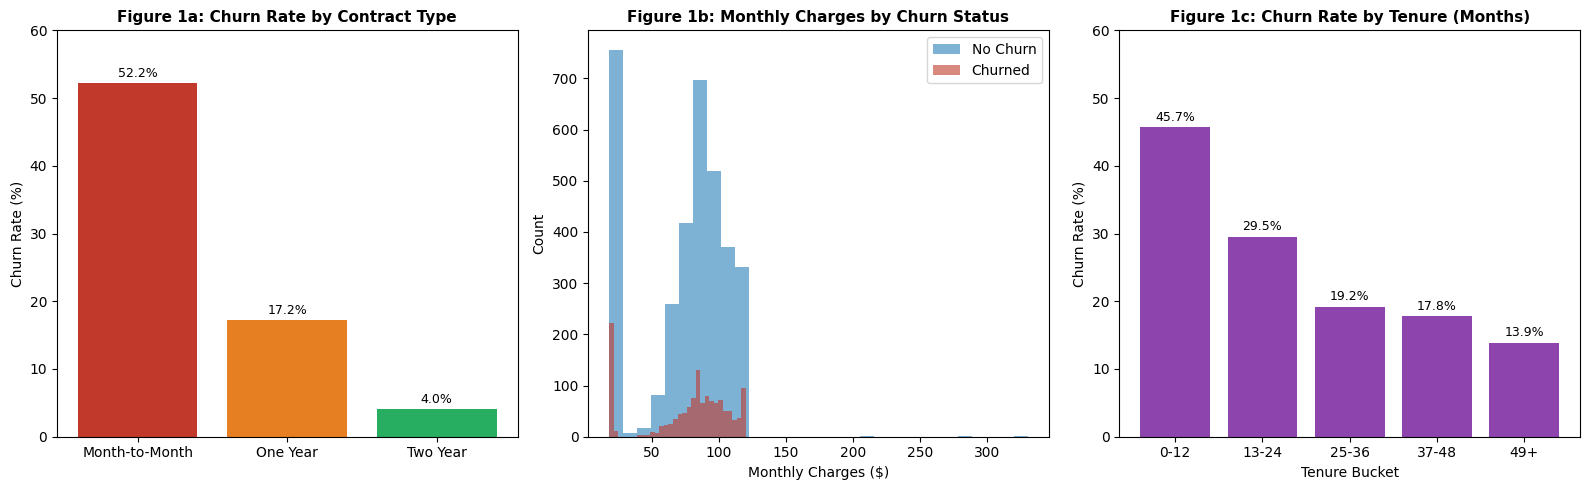

Figure 1: EDA charts saved as eda_charts.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Chart 1: Churn Rate by Contract Type ---
df["Tenure_Bucket_temp"] = pd.cut(
    df["Tenure_Months"], bins=[0, 12, 24, 36, 48, 72],
    labels=["0-12", "13-24", "25-36", "37-48", "49+"]
)
# Reconstruct contract labels from one-hot columns
def get_contract(row):
    if row.get("Contract_One year", 0) == 1:
        return "One Year"
    elif row.get("Contract_Two year", 0) == 1:
        return "Two Year"
    return "Month-to-Month"

df["Contract_Label"] = df.apply(get_contract, axis=1)
churn_by_contract = df.groupby("Contract_Label")["Churn"].mean() * 100
order = ["Month-to-Month", "One Year", "Two Year"]
churn_by_contract = churn_by_contract.reindex(order)
colors_bar = ["#c0392b", "#e67e22", "#27ae60"]
bars = axes[0].bar(churn_by_contract.index, churn_by_contract.values, color=colors_bar)
axes[0].set_title("Figure 1a: Churn Rate by Contract Type", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 60)
for bar, val in zip(bars, churn_by_contract.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{val:.1f}%", ha="center", va="bottom", fontsize=9)

# --- Chart 2: Monthly Charges Distribution by Churn ---
churners = df[df["Churn"] == 1]["Monthly_Charges"]
non_churners = df[df["Churn"] == 0]["Monthly_Charges"]
axes[1].hist(non_churners, bins=30, alpha=0.6, label="No Churn", color="#2980b9")
axes[1].hist(churners, bins=30, alpha=0.6, label="Churned", color="#c0392b")
axes[1].set_title("Figure 1b: Monthly Charges by Churn Status", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Monthly Charges ($)")
axes[1].set_ylabel("Count")
axes[1].legend()

# --- Chart 3: Churn Rate by Tenure Bucket ---
churn_by_tenure = df.groupby("Tenure_Bucket_temp")["Churn"].mean() * 100
axes[2].bar(churn_by_tenure.index.astype(str), churn_by_tenure.values, color="#8e44ad")
axes[2].set_title("Figure 1c: Churn Rate by Tenure (Months)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Tenure Bucket")
axes[2].set_ylabel("Churn Rate (%)")
axes[2].set_ylim(0, 60)
for i, v in enumerate(churn_by_tenure.values):
    axes[2].text(i, v + 0.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

df.drop(columns=["Tenure_Bucket_temp", "Contract_Label"], inplace=True)

plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 1: EDA charts saved as eda_charts.png")

## 5. Feature Scaling & Train/Test Split

In [5]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Training set : {X_train.shape[0]} records")
print(f"Test set     : {X_test.shape[0]} records")
print(f"\nClass balance in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nStandardScaler applied. Features now have mean ~0 and std ~1.")

Training set : 3838 records
Test set     : 960 records

Class balance in training set:
Churn
0    0.721
1    0.279
Name: proportion, dtype: float64

StandardScaler applied. Features now have mean ~0 and std ~1.


## 6. Model Building & Evaluation

In [6]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    train_acc = accuracy_score(y_tr, model.predict(X_tr))
    y_pred = model.predict(X_te)
    acc   = accuracy_score(y_te, y_pred)
    prec  = precision_score(y_te, y_pred)
    rec   = recall_score(y_te, y_pred)
    f1    = f1_score(y_te, y_pred)
    cm    = confusion_matrix(y_te, y_pred)
    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(f"  Training Accuracy : {train_acc:.4f}")
    print(f"  Test Accuracy     : {acc:.4f}   (Gap: {train_acc - acc:.4f})")
    print(f"  Precision         : {prec:.4f}")
    print(f"  Recall            : {rec:.4f}")
    print(f"  F1 Score          : {f1:.4f}")
    print(f"  Confusion Matrix:\n{cm}")
    return {"Model": name, "Train Acc": round(train_acc, 4),
            "Test Acc": round(acc, 4), "Precision": round(prec, 4),
            "Recall": round(rec, 4), "F1": round(f1, 4)}

results = []

# --- Model 1: Logistic Regression (Baseline) ---
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)
results.append(evaluate_model("Model 1: Logistic Regression (Baseline)",
                               lr, X_train_sc, y_train, X_test_sc, y_test))

# --- Model 2: Simple Neural Network (1 hidden layer, 16 neurons) ---
nn1 = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, random_state=42)
nn1.fit(X_train_sc, y_train)
results.append(evaluate_model("Model 2: Simple Neural Network (16 neurons)",
                               nn1, X_train_sc, y_train, X_test_sc, y_test))

# --- Model 3: Deeper Neural Network (2 hidden layers: 32, 16 neurons) ---
nn2 = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)
nn2.fit(X_train_sc, y_train)
results.append(evaluate_model("Model 3: Deeper Neural Network (32-16 neurons)",
                               nn2, X_train_sc, y_train, X_test_sc, y_test))


  Model 1: Logistic Regression (Baseline)
  Training Accuracy : 0.7796
  Test Accuracy     : 0.7656   (Gap: 0.0139)
  Precision         : 0.5808
  Recall            : 0.5655
  F1 Score          : 0.5731
  Confusion Matrix:
[[584 109]
 [116 151]]

  Model 2: Simple Neural Network (16 neurons)
  Training Accuracy : 0.8207
  Test Accuracy     : 0.7531   (Gap: 0.0676)
  Precision         : 0.5615
  Recall            : 0.5131
  F1 Score          : 0.5362
  Confusion Matrix:
[[586 107]
 [130 137]]

  Model 3: Deeper Neural Network (32-16 neurons)
  Training Accuracy : 0.9500
  Test Accuracy     : 0.7063   (Gap: 0.2437)
  Precision         : 0.4723
  Recall            : 0.4794
  F1 Score          : 0.4758
  Confusion Matrix:
[[550 143]
 [139 128]]


## 7. Model Comparison


Model Comparison Table:
                                         Model  Train Acc  Test Acc  Precision  Recall     F1
       Model 1: Logistic Regression (Baseline)     0.7796    0.7656     0.5808  0.5655 0.5731
   Model 2: Simple Neural Network (16 neurons)     0.8207    0.7531     0.5615  0.5131 0.5362
Model 3: Deeper Neural Network (32-16 neurons)     0.9500    0.7063     0.4723  0.4794 0.4758


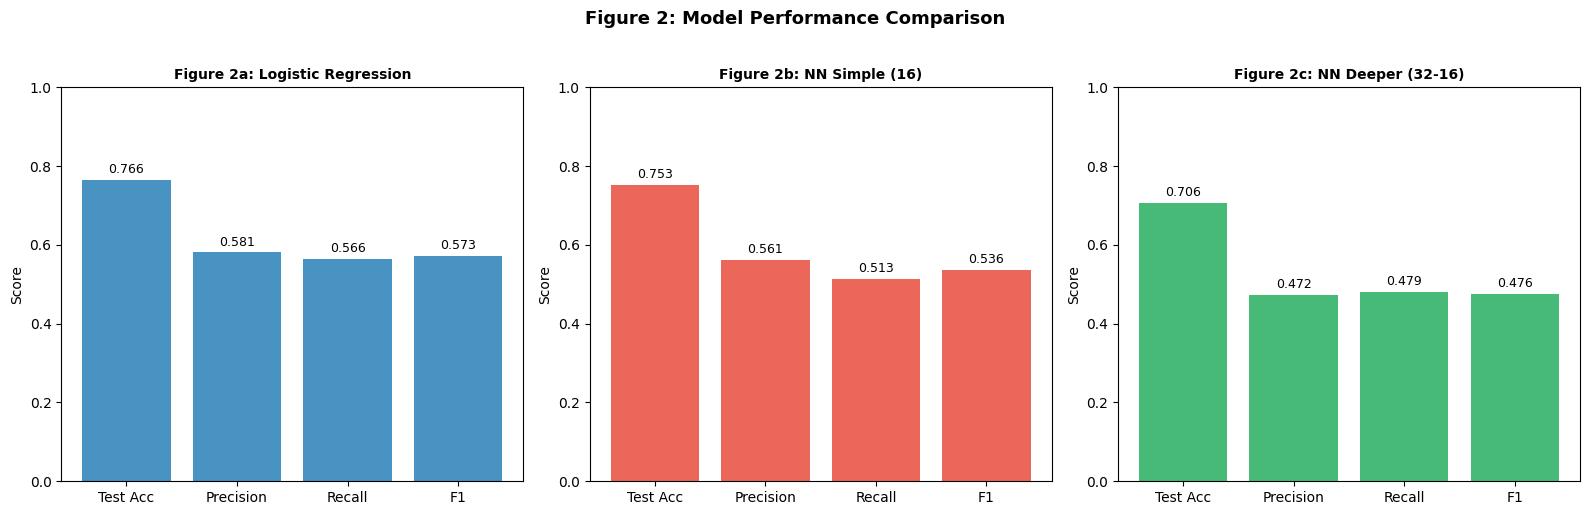

Figure 2: Model comparison saved as model_comparison.png

Overfitting Check (Train Accuracy vs Test Accuracy):
  Model 1: Logistic Regression (Baseline)    | Gap: 0.0140
  Model 2: Simple Neural Network (16 neurons | Gap: 0.0676
  Model 3: Deeper Neural Network (32-16 neur | Gap: 0.2437  << OVERFITTING


In [7]:
results_df = pd.DataFrame(results)
print("\nModel Comparison Table:")
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ["Test Acc", "Precision", "Recall", "F1"]
colors = ["#2980b9", "#e74c3c", "#27ae60"]
short_names = ["Logistic Regression", "NN Simple (16)", "NN Deeper (32-16)"]

for i, ax in enumerate(axes):
    row = results_df.iloc[i]
    vals = [row[m] for m in metrics]
    bars = ax.bar(metrics, vals, color=colors[i], alpha=0.85)
    ax.set_ylim(0, 1.0)
    ax.set_title(f"Figure 2{chr(97+i)}: {short_names[i]}", fontsize=10, fontweight="bold")
    ax.set_ylabel("Score")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{v:.3f}", ha="center", va="bottom", fontsize=9)

plt.suptitle("Figure 2: Model Performance Comparison", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 2: Model comparison saved as model_comparison.png")

print("\nOverfitting Check (Train Accuracy vs Test Accuracy):")
for _, row in results_df.iterrows():
    gap = row["Train Acc"] - row["Test Acc"]
    flag = "  << OVERFITTING" if gap > 0.10 else ""
    print(f"  {row['Model'][:42]:42s} | Gap: {gap:.4f}{flag}")